In [18]:
!pip install importlib_resources

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrade pip


In [1]:
import tensorflow_datasets as tfds
import tensorflow as tf
from tensorflow.keras.utils import to_categorical

I0000 00:00:1793016871.376737   22123 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793016872.069121   22123 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793016874.574501   22123 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
## Loading images and labels
(train_ds, train_labels), (test_ds, test_labels) = tfds.load("tf_flowers",
    split=["train[60%:70%]", "train[70%:80%]"], ## Train test split
    batch_size=-1,
    as_supervised=True,  # Include labels
)

E0000 00:00:1793016877.041366   22123 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
I0000 00:00:1793016877.121501   22162 tf_record_dataset_op.cc:396] The default buffer size is 262144, which is overridden by the user specified `buffer_size` of 8388608
W0000 00:00:1793016877.375475   22231 cpu_allocator_impl.cc:82] Allocation of 464498688 exceeds 10% of free system memory.
W0000 00:00:1793016877.873735   22300 cpu_allocator_impl.cc:82] Allocation of 309336960 exceeds 10% of free system memory.


In [3]:
## check existing image size
train_ds[0].shape

TensorShape([412, 1024, 3])

In [4]:
## Resizing images
train_ds = tf.image.resize(train_ds, (150, 150))
test_ds = tf.image.resize(test_ds, (150, 150))

W0000 00:00:1793016885.368807   22123 cpu_allocator_impl.cc:82] Allocation of 99090000 exceeds 10% of free system memory.
W0000 00:00:1793016885.516226   22123 cpu_allocator_impl.cc:82] Allocation of 99090000 exceeds 10% of free system memory.


In [5]:
train_labels

<tf.Tensor: shape=(367,), dtype=int64, numpy=
array([3, 0, 4, 4, 0, 4, 3, 1, 0, 3, 2, 2, 0, 4, 4, 1, 4, 2, 0, 0, 2, 0,
       2, 1, 0, 0, 1, 2, 0, 1, 3, 3, 1, 2, 4, 4, 1, 0, 4, 4, 0, 2, 1, 2,
       3, 1, 4, 4, 2, 4, 3, 3, 0, 3, 2, 3, 3, 2, 3, 0, 4, 3, 4, 2, 3, 1,
       3, 2, 2, 1, 3, 0, 4, 3, 2, 1, 3, 0, 3, 4, 0, 0, 0, 2, 3, 2, 0, 3,
       1, 0, 4, 1, 2, 3, 0, 0, 4, 2, 2, 4, 1, 2, 2, 0, 0, 0, 4, 3, 3, 3,
       1, 2, 4, 1, 0, 3, 1, 0, 0, 3, 0, 2, 0, 4, 2, 0, 2, 3, 3, 3, 2, 0,
       3, 0, 0, 4, 4, 1, 4, 0, 4, 0, 1, 3, 2, 0, 2, 1, 2, 0, 2, 4, 3, 4,
       4, 4, 4, 0, 4, 4, 2, 1, 3, 0, 2, 1, 3, 2, 4, 0, 1, 2, 4, 0, 2, 4,
       3, 0, 4, 2, 0, 3, 2, 0, 0, 2, 3, 1, 4, 0, 0, 3, 0, 4, 1, 4, 4, 3,
       3, 1, 0, 3, 4, 0, 1, 3, 3, 0, 4, 4, 3, 1, 1, 2, 2, 0, 2, 3, 1, 4,
       3, 3, 2, 2, 0, 0, 0, 3, 3, 2, 2, 1, 0, 3, 1, 2, 2, 2, 4, 4, 2, 2,
       1, 3, 3, 3, 1, 0, 2, 1, 3, 2, 0, 3, 2, 3, 0, 0, 1, 1, 2, 0, 0, 4,
       2, 2, 4, 3, 2, 0, 1, 1, 4, 2, 3, 1, 0, 4, 1, 1, 4, 4, 0, 4, 0, 3,
     

In [6]:
## Transforming labels to correct format
train_labels = to_categorical(train_labels, num_classes=5)
test_labels = to_categorical(test_labels, num_classes=5)

In [7]:
train_labels[0]

<tf.Tensor: shape=(5,), dtype=float32, numpy=array([0., 0., 0., 1., 0.], dtype=float32)>

In [8]:
from tensorflow.keras.applications.vgg16 import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

In [9]:
train_ds[0].shape

TensorShape([150, 150, 3])

In [10]:
## Loading VGG16 model
base_model = VGG16(weights="imagenet", include_top=False, input_shape=train_ds[0].shape)

In [11]:
## will not train base mode
# Freeze Parameters in model's lower convolutional layers
base_model.trainable = False

In [12]:
## Preprocessing input
train_ds = preprocess_input(train_ds)
test_ds = preprocess_input(test_ds)

W0000 00:00:1793016903.216086   22123 cpu_allocator_impl.cc:82] Allocation of 99090000 exceeds 10% of free system memory.


In [13]:
## model details
base_model.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 150, 150, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 150, 150, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 75, 75, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 75, 75, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 37, 37, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 18, 18, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 18, 18, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 9, 9, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 4, 4, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

In [14]:
#add our layers on top of this model
from tensorflow.keras import layers, models

flatten_layer = layers.Flatten()
dense_layer_1 = layers.Dense(50, activation='relu')
dense_layer_2 = layers.Dense(20, activation='relu')
prediction_layer = layers.Dense(5, activation='softmax')


model = models.Sequential([
    base_model,
    flatten_layer,
    dense_layer_1,
    dense_layer_2,
    prediction_layer
])

In [15]:
from tensorflow.keras.callbacks import EarlyStopping

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy'],
)

In [16]:
es = EarlyStopping(monitor='val_accuracy', mode='max', patience=5,  restore_best_weights=True)

In [17]:
history=model.fit(train_ds, train_labels, epochs=5, validation_split=0.2, batch_size=32, callbacks=[es])

Epoch 1/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step - accuracy: 0.2935 - loss: 4.4375 - val_accuracy: 0.4189 - val_loss: 2.4564
Epoch 2/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 18s 2s/step - accuracy: 0.6075 - loss: 1.4050 - val_accuracy: 0.5405 - val_loss: 1.8814
Epoch 3/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step - accuracy: 0.6724 - loss: 0.9216 - val_accuracy: 0.5270 - val_loss: 1.6485
Epoch 4/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 18s 2s/step - accuracy: 0.7986 - loss: 0.5393 - val_accuracy: 0.5000 - val_loss: 1.9694
Epoch 5/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step - accuracy: 0.8874 - loss: 0.3502 - val_accuracy: 0.5541 - val_loss: 1.9095


In [19]:
los,accurac=model.evaluate(test_ds,test_labels)
print("Loss: ",los,"Accuracy: ", accurac)

12/12 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.5232 - loss: 1.9036
Loss:  1.9035581350326538 Accuracy:  0.5231607556343079


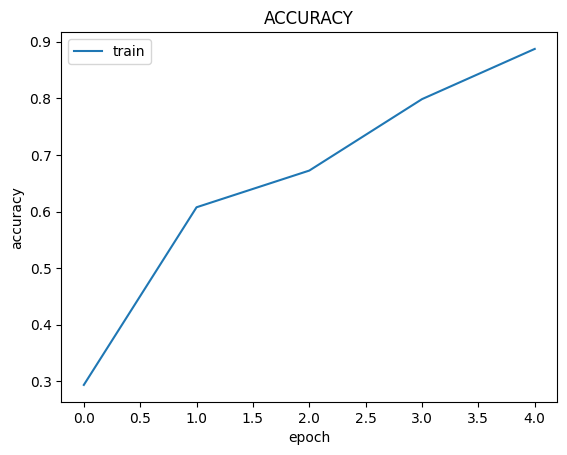

In [20]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'])
plt.title('ACCURACY')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train'],loc='upper left')
plt.show()

In [21]:
import numpy as np
import pandas as pd
y_pred = model.predict(test_ds)
y_classes = [np.argmax(element) for element in y_pred]
#to_categorical(y_classes, num_classes=5)
#to_categorical(test_labels, num_classes=5)
print(y_classes[:10])
print("\nTest")
print(test_labels[:10])

12/12 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step
[np.int64(4), np.int64(1), np.int64(2), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(3)]

Test
tf.Tensor(
[[0. 0. 0. 0. 1.]
 [1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 0. 1. 0.]
 [1. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0.]
 [1. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 0. 1. 0.]], shape=(10, 5), dtype=float32)
